# Proj 1: Student Marks Predictor

## Objective
Predict student marks using the number of hours studied
## Machine learning type
Supervised learing
## Algorithm
Linear Regression


In [ ]:
study_hours = [1, 2, 3, 4, 5, 6]
marks = [20, 30, 40, 50, 60, 70]

print(study_hours)
print(marks)

[1, 2, 3, 4, 5, 6]
[20, 30, 40, 50, 60, 70]


In [ ]:
import pandas as pd
data ={"Study_hours":study_hours,"Marks":marks}
df=pd.DataFrame(data)
df

,Study_hours,Marks
0,1,20
1,2,30
2,3,40
3,4,50
4,5,60
5,6,70


In [ ]:
print(df.head())
print("Shape:",df.shape)
print(df.describe())

   Study_hours  Marks
0            1     20
1            2     30
2            3     40
3            4     50
4            5     60
Shape: (6, 2)
       Study_hours      Marks
count     6.000000   6.000000
mean      3.500000  45.000000
std       1.870829  18.708287
min       1.000000  20.000000
25%       2.250000  32.500000
50%       3.500000  45.000000
75%       4.750000  57.500000
max       6.000000  70.000000


In [ ]:
x=df[["Study_hours"]]
y=df["Marks"]
print("Input features (X):")
print(x)
print("\nTarget values(Y):")
print(y)

Input features (X):
   Study_hours
0            1
1            2
2            3
3            4
4            5
5            6

Target values(Y):
0    20
1    30
2    40
3    50
4    60
5    70
Name: Marks, dtype: int64


In [ ]:
from sklearn.linear_model import LinearRegression
model=LinearRegression()
model.fit(x,y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[10.]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Study_hours']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,10
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [ ]:
print("Slope:",model.coef_[0])
print("Intercept:",model.intercept_)

Slope: 10.000000000000002
Intercept: 9.999999999999993


In [ ]:
new_student=pd.DataFrame({"Study_hours":[7]})
prediction=model.predict(new_student)
print("Predicted marks:",prediction[0])

Predicted marks: 80.0


In [ ]:
new_student=pd.DataFrame({"Study_hours":[9]})
prediction=model.predict(new_student)
print("Predicted marks:",prediction[0])

Predicted marks: 100.0


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    x, y, test_size=0.33, random_state=42
)

print("Training inputs:")
print(X_train)

print("Testing inputs:")
print(X_test)

Training inputs:
   Study_hours
5            6
2            3
4            5
3            4
Testing inputs:
   Study_hours
0            1
1            2


In [ ]:
print("Original dataset shape:", x.shape)

print("Training features shape:", X_train.shape)
print("Training targets shape:", y_train.shape)

print("Testing features shape:", X_test.shape)
print("Testing targets shape:", y_test.shape)

Original dataset shape: (6, 1)
Training features shape: (4, 1)
Training targets shape: (4,)
Testing features shape: (2, 1)
Testing targets shape: (2,)


In [ ]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

print("Slope:", model.coef_[0])
print("Intercept:", model.intercept_)

Slope: 10.0
Intercept: 10.0


In [ ]:
predictions = model.predict(X_test)

print("Testing study hours:")
print(X_test)

print("Actual marks:")
print(y_test)

print("Predicted marks:")
print(predictions)


Testing study hours:
   Study_hours
0            1
1            2
Actual marks:
0    20
1    30
Name: Marks, dtype: int64
Predicted marks:
[20. 30.]


In [ ]:
model=LinearRegression()
model.fit(X_train,y_train)
predictions=model.predict(X_test)
print("Actual marks:",y_test.to_list())
print("Predicted marks:",predictions)

Actual marks: [20, 30]
Predicted marks: [20. 30.]


In [ ]:
from sklearn.metrics import mean_absolute_error
mae=mean_absolute_error(y_test,predictions)
print("Mean absolute error:",mae)

Mean absolute error: 0.0


In [ ]:
from sklearn.metrics import r2_score
r2=r2_score(y_test,predictions)
print("R2 score",r2)          # 1.0 perfect,  0.0 no improvement over simply predicting target calue , below 0 worse than average value baseline

R2 score 1.0


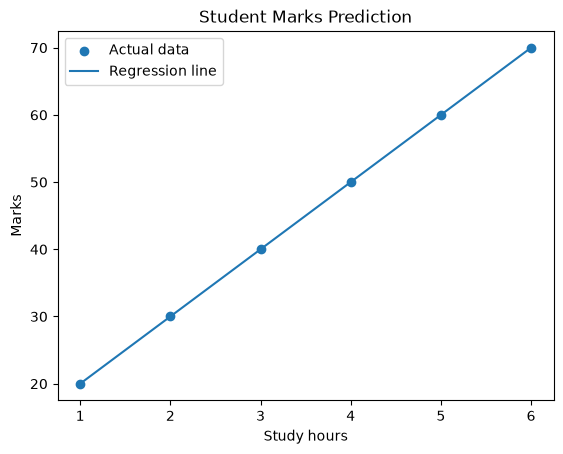

In [ ]:
import matplotlib.pyplot as plt
plt.scatter(x,y,label="Actual data")
plt.plot(x,model.predict(x),label="Regression line")
plt.xlabel("Study hours")
plt.ylabel("Marks")
plt.title("Student Marks Prediction")
plt.legend()
plt.show()

In [ ]:
data={"Study_hours":[1,2,3,4,5,6,7,8,9,10],"Marks":[18,32,35,48,55,65,68,82,85,96]}
df=pd.DataFrame(data)
print(df)

   Study_hours  Marks
0            1     18
1            2     32
2            3     35
3            4     48
4            5     55
5            6     65
6            7     68
7            8     82
8            9     85
9           10     96


In [ ]:
x=df[["Study_hours"]]
y=df["Marks"]
print("Input shape:",x.shape)
print("Output shape:",y.shape)

Input shape: (10, 1)
Output shape: (10,)


In [ ]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(
    x,y,test_size=0.2,random_state=10
)
print("Training examples:",len(x_train))
print("Testing examples:",len(x_test))

Training examples: 8
Testing examples: 2


In [ ]:
model=LinearRegression()
model.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[8.41]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['Study_hours']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,12.81
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [ ]:
print("Slope:",model.coef_[0])
print("Intercept:",model.intercept_)

Slope: 8.407045009784731
Intercept: 12.812133072407072


In [ ]:
predictions=model.predict(x_test)
print("Study hours:")
print(x_test)
print("Actual marks:")
print(y_test)
print("Predicted marks:")
print(predictions)

Study hours:
   Study_hours
8            9
2            3
Actual marks:
8    85
2    35
Name: Marks, dtype: int64
Predicted marks:
[88.47553816 38.0332681 ]


In [ ]:
from sklearn.metrics import mean_absolute_error,r2_score
mae=mean_absolute_error(y_test,predictions)
r2=r2_score(y_test,predictions)
print("MAE:",mae)
print("R2 score:",r2)

MAE: 3.2544031311154598
R2 score: 0.9829759352943654


In [ ]:
train_predictions=model.predict(x_train)
test_predictions=model.predict(x_test)
train_mae=mean_absolute_error(y_train,train_predictions)
test_mae=mean_absolute_error(y_test,test_predictions)
print("Train mae:",train_mae)
print("Test mae:",test_mae)

Train mae: 1.9408023483365904
Test mae: 3.2544031311154598


In [ ]:
data={"Study hours":[1,2,3,4,5,6,7,8,9,10], "Attendance":[50,55,60,65,70,75,80,85,90,95], "Marks":[18,32,35,48,55,65,68,82,85,96]}
df=pd.DataFrame(data)
x=df[["Study hours","Attendance"]]
y=df["Marks"]

model=LinearRegression()
model.fit(x,y)

print(model.coef_)
print(model.intercept_)

[0.32121212 1.60606061]
-59.80606060606059


In [ ]:
new_student=pd.DataFrame({"Study hours":[6], "Attendance":[80]})
prediction=model.predict(new_student)
print ("Predicted Marks:",prediction)

Predicted Marks: [70.60606061]


In [ ]:
import joblib
joblib.dump(model,"student_marks_model.pkl")
loaded_model=joblib.load("student_marks_model.pkl")
print(loaded_model.predict(new_student))

[70.60606061]
